# 02 Matching and EDA

Matching report plus the five Week 2 questions: unknown rate by community area, by year-built band, by diameter, by utility-side material, and replacement counts by year (Gate 1). Areas with fewer than 5 lines are suppressed in every table and map.

In [1]:
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from lll import PROCESSED_DIR, sources
from lll.features import line_status

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)
SNAP = "20250414"
FIG = PROCESSED_DIR.parent.parent / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
from lll.equity import SUPPRESSION_MIN
from lll.geocode import MATCHED, matching_report

m = pd.read_parquet(PROCESSED_DIR / f"master_chicago_{SNAP}.parquet")
areas = {lvl: pd.read_parquet(PROCESSED_DIR / f"areas_{lvl}_chicago_{SNAP}.parquet")
         for lvl in ["community_area", "tract", "ward"]}
print(f"{len(m):,} lines")

491,705 lines


## Matching report

In [2]:
rep = matching_report(m)
print(f"matched or geocoded: {rep.loc[rep.matched, 'share'].sum():.2%}")
rep

matched or geocoded: 98.28%


,code,rows,share,description,matched
0,matched_address,447307,0.910,Exact match on normalized address,True
1,matched_nearby,26001,0.053,Nearest parcel on the same street and side wit...,True
2,geocoded_census,9951,0.020,Matched by Census Geocoder batch,True
3,census_error,7585,0.015,Census Geocoder request failed,False
4,census_no_match,367,0.001,Census Geocoder returned no match,False
5,intersection,346,0.001,"Address is a street intersection, not a building",False
6,census_tie,123,0.000,Census Geocoder returned a tie,False
7,parse_error,25,0.000,usaddress could not parse the address,False


In [3]:
located = m.match_method.isin(MATCHED)
cov = pd.DataFrame({c: [located.sum(), m.loc[located, c].notna().mean()]
                    for c in ["block", "block_group", "tract", "ward", "community_area"]},
                   index=["located lines", "share with geography"]).T
print("located lines outside city limits (no ward/community area):", int((m.in_city == False).sum()))
cov

located lines outside city limits (no ward/community area): 153


,located lines,share with geography
block,"483,259.000",1.000
block_group,"483,259.000",1.000
tract,"483,259.000",1.000
ward,"483,259.000",1.000
community_area,"483,259.000",1.000


In [4]:
by_ca = (m.assign(located=located).groupby("community_area")["located"].mean())
print("match rate by community area: min {:.1%}, median {:.1%}".format(by_ca.min(), by_ca.median()))
unmatched_status = m.loc[~located, "line_status"].value_counts(normalize=True)
pd.DataFrame({"unmatched": unmatched_status, "all": m.line_status.value_counts(normalize=True)})

match rate by community area: min 100.0%, median 100.0%


,unmatched,all
line_status,,
GRR,0.013,0.021
Lead,0.170,0.307
Non-Lead,0.748,0.161
Unknown,0.069,0.511


## Q1. Unknown rate by community area

In [5]:
ca = areas["community_area"].merge(
    sources.community_areas()[["community_area", "community_area_name"]], on="community_area")
ca = ca.sort_values("share_unknown", ascending=False)
cols = ["community_area_name", "total_lines", "share_unknown", "share_lead", "share_grr", "share_nonlead"]
print("highest unknown share"); display(ca[cols].head(10))
print("lowest unknown share"); display(ca[cols].tail(10))
print(f"range {ca.share_unknown.min():.1%} to {ca.share_unknown.max():.1%}")

highest unknown share


,community_area_name,total_lines,share_unknown,share_lead,share_grr,share_nonlead
24,Lower West Side,5280,0.678,0.130,0.009,0.184
61,West Lawn,7508,0.674,0.281,0.009,0.036
23,South Lawndale,9193,0.661,0.263,0.010,0.066
58,West Elsdon,4249,0.657,0.268,0.007,0.068
59,Gage Park,6596,0.652,0.285,0.017,0.046
10,Belmont Cragin,13240,0.638,0.288,0.017,0.058
62,Chicago Lawn,10621,0.623,0.313,0.025,0.038
73,Ohare,1293,0.614,0.289,0.003,0.094
53,Brighton Park,7435,0.606,0.280,0.020,0.095
64,Englewood,6089,0.603,0.264,0.044,0.090


lowest unknown share


,community_area_name,total_lines,share_unknown,share_lead,share_grr,share_nonlead
28,Douglas,1316,0.422,0.122,0.008,0.448
66,Lincoln Park,8535,0.422,0.081,0.006,0.492
27,Armour Square,1733,0.415,0.152,0.010,0.422
55,Lake View,9722,0.394,0.122,0.010,0.474
44,North Center,7253,0.344,0.221,0.017,0.418
20,Near West Side,5537,0.331,0.092,0.009,0.568
75,Near North Side,3102,0.288,0.043,0.013,0.657
29,Oakland,615,0.216,0.054,0.007,0.724
25,Loop,839,0.162,0.007,0.007,0.824
26,Near South Side,1231,0.094,0.024,0.002,0.879


range 9.4% to 67.8%


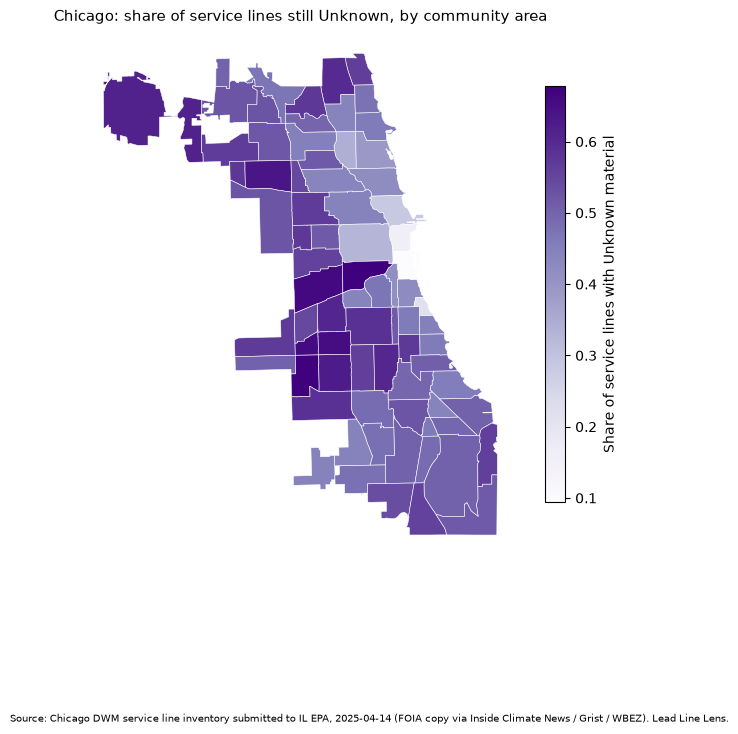

In [6]:
g = sources.community_areas().merge(ca, on=["community_area", "community_area_name"], how="left")
fig, ax = plt.subplots(figsize=(7, 9))
g.plot(column="share_unknown", cmap="Purples", legend=True, ax=ax, edgecolor="white", linewidth=0.4,
       legend_kwds={"label": "Share of service lines with Unknown material", "shrink": 0.6},
       missing_kwds={"color": "lightgrey", "label": "suppressed (<5 lines)"})
ax.set_axis_off()
ax.set_title("Chicago: share of service lines still Unknown, by community area", fontsize=11)
fig.text(0.02, 0.02, "Source: Chicago DWM service line inventory submitted to IL EPA, 2025-04-14 "
         "(FOIA copy via Inside Climate News / Grist / WBEZ). Lead Line Lens.", fontsize=7)
fig.savefig(FIG / "map1_unknown_share_community_area.png", dpi=160, bbox_inches="tight")
plt.show()

## Q2. Unknown rate by year-built band

Year built comes from the Assessor and attaches only to exact parcel matches.

In [7]:
band = sources.year_band(m.year_built).astype(object).fillna("year not known")
known = m.line_status.ne("Unknown")
t = pd.DataFrame({"lines": band.value_counts(),
                  "share_unknown": m.line_status.eq("Unknown").groupby(band).mean(),
                  "lead_like_among_known": m.line_status.isin(["Lead", "GRR"])[known].groupby(band[known]).mean()})
t.reindex(["<1900", "1900-29", "1930-49", "1950-69", "1970-85", "1986-99", "2000+", "year not known"])

,lines,share_unknown,lead_like_among_known
year_built,,,
<1900,64689,0.602,0.788
1900-29,168332,0.545,0.882
1930-49,42701,0.504,0.934
1950-69,97126,0.552,0.943
1970-85,9589,0.590,0.796
1986-99,13644,0.041,0.018
2000+,23948,0.027,0.017
year not known,71676,0.536,0.273


## Q3. Unknown rate by diameter

Chicago's inventory has no diameter field. East Dundee is the only test system that records it (ServSize, 85 of 1,497 lines).

In [8]:
ed = sources.east_dundee()
ed["status"] = line_status(ed.utility_side_material, ed.customer_side_material)
d = ed.diameter_in.map(lambda x: "not recorded" if pd.isna(x) else f'{x:g}"')
pd.crosstab(d, ed.status, margins=True)

status,GRR,Lead,Non-Lead,Unknown,All
diameter_in,,,,,
"0.75""",0,13,35,0,48
"1""",0,0,34,0,34
"2""",0,0,1,0,1
"3""",0,0,2,0,2
not recorded,13,230,1039,130,1412
All,13,243,1111,130,1497


## Q4. Customer-side status by utility-side material (Chicago)

In [9]:
ct = pd.crosstab(m.utility_side_material, m.customer_side_material, normalize="index")
ct["lines"] = m.utility_side_material.value_counts()
ct

customer_side_material,GRR,Lead,Non-Lead,Unknown,lines
utility_side_material,,,,,
GRR,0.694,0.092,0.118,0.096,314
Lead,0.042,0.298,0.056,0.604,50455
Non-Lead,0.004,0.034,0.942,0.020,83954
Unknown,0.028,0.273,0.029,0.670,356982


## Q5. Replacements by year

In [10]:
yr = m.replacement_date.dt.year
print(f"lines with a replacement date: {yr.notna().sum():,}; flagged previously replaced: {int(m.prev_lead_replaced.sum()):,}; "
      f"either: {int(m.replaced.sum()):,}")
yr.value_counts().sort_index().rename("replacements").to_frame().T

lines with a replacement date: 10,640; flagged previously replaced: 7,875; either: 10,640


replacement_date,"2,017.000","2,021.000","2,022.000","2,023.000","2,024.000","2,025.000"
replacements,1,34,349,4174,4753,1329


## Map 2. Known lead or GRR share by census tract

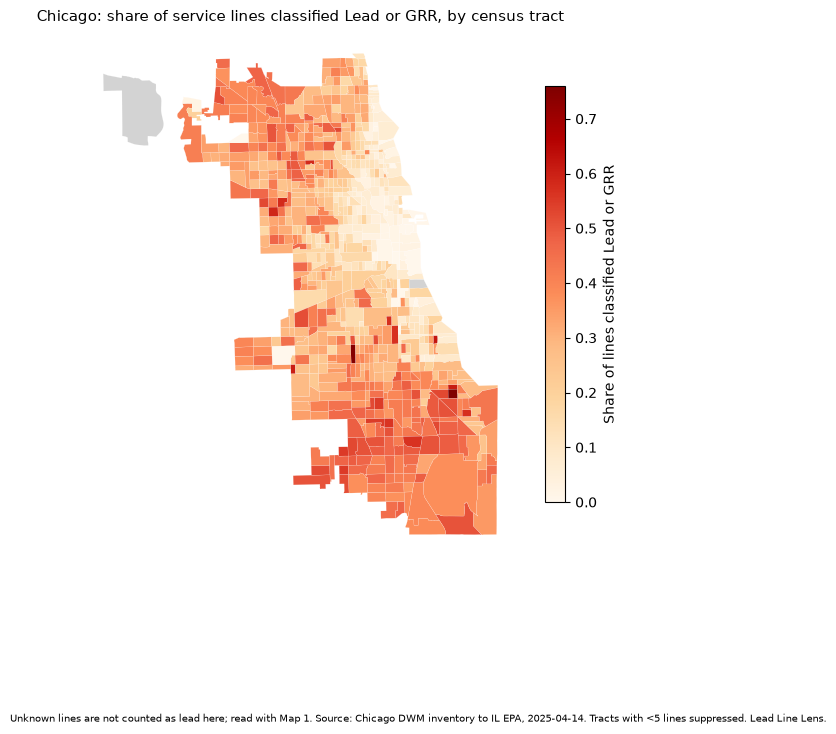

tracts suppressed: 12 of 811


In [11]:
tr = areas["tract"]
tg = sources.tracts().merge(tr, on="tract", how="left")
tg["share_lead_like"] = tg.share_lead + tg.share_grr
fig, ax = plt.subplots(figsize=(7, 9))
tg.plot(column="share_lead_like", cmap="OrRd", legend=True, ax=ax, edgecolor="white", linewidth=0.1,
        legend_kwds={"label": "Share of lines classified Lead or GRR", "shrink": 0.6},
        missing_kwds={"color": "lightgrey", "label": "suppressed (<5 lines) or no lines"})
ax.set_axis_off()
ax.set_title("Chicago: share of service lines classified Lead or GRR, by census tract", fontsize=11)
fig.text(0.02, 0.02, "Unknown lines are not counted as lead here; read with Map 1. Source: Chicago DWM "
         "inventory to IL EPA, 2025-04-14. Tracts with <5 lines suppressed. Lead Line Lens.", fontsize=7)
fig.savefig(FIG / "map2_lead_share_tract.png", dpi=160, bbox_inches="tight")
plt.show()
print("tracts suppressed:", int(tr.suppressed.sum()), "of", len(tr))